# VaR / ES d'un portefeuille de dérivés de corrélation — Full repricing vs proxies (Full Chebyshev, Tensor-Train)

**Règles de cette version** (détail et écarts avec la version précédente : `CHANGEMENTS.md`)

| Élément | Choix |
|---|---|
| Full repricing | **un seul**, **unitaire** (instrument par instrument, 100 pricings par scénario), régime **noCRN** : générateur **re-créé avec la même seed** à chaque pricing (coût d'un pricer front office) |
| Trajectoires | **100 000** pour **tous** les pricings (full repricing, V0, nœuds des proxies) |
| Scénarios | **10 000** chocs corrélés sur les 25 sous-jacents, **même** paquet pour 1j et 10j ; le groupe $d$ lit le préfixe $s_{1:d}$ |
| Mesures | pour **1j** et **10j** séparément : **VaR 99 %**, **ES 97,5 %**, **ES 99 %** |
| Boîte des proxies | enveloppe empirique des scénarios 1j + 10j : $\text{lo}_i = 0{,}99\min_{k,h}s^{(k)}_{h,i}$, $\text{hi}_i = 1{,}01\max_{k,h}s^{(k)}_{h,i}$ |
| Nœuds des proxies | pricer de groupe **CRN** (paquet figé), Full Chebyshev ($d=5$) et TT ($d=10\dots25$) |
| Cache | **tout** : scénarios, chaque pricing unitaire (valeur + temps), nœuds (valeur + temps), fits, évaluations, tableaux, figures. Reprise exacte après interruption. |

Le full repricing est long (ordre de grandeur mesuré : ~4 s par scénario pour le portefeuille, ~20 h en séquentiel). Il peut être lancé **ici** ou, mieux, en ligne de commande : `nohup python run_all.py --stage fr --workers 8 > fr.log 2>&1 &` ; ce notebook relit ensuite le même cache.

## 0. Imports

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath("."))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from config import ExperimentConfig
from model import OPTION_TYPES
from portfolio import build_market, build_portfolio, check_portfolio, basket_level
from risk import get_scenarios, empirical_box, inside_box, scenarios_dir
import full_repricing as FR
from proxies import run_group_proxy
import analysis as A

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 250)
pd.set_option("display.max_colwidth", 80)

In [2]:
# MoCaX : necessaire UNIQUEMENT pour construire un proxy absent du cache.
MOCAX_ROOT = os.path.join(os.path.expanduser("~"), "mocax")
mocaxpy = me = None
try:
    from mocax_loader import load_mocax
    from mocax_extend_loader import load_mocax_extend
    mocaxpy = load_mocax(search_roots=[MOCAX_ROOT])
    me = load_mocax_extend(search_roots=[MOCAX_ROOT])
except Exception as exc:
    print("MoCaX non charge (%s) -> proxies lus du cache uniquement." % exc)

mocaxpy trouve dans : /home/oussama/mocax/MoCaXSuite-1.2.0/MoCaX/Linux/gmake/64bit/Python/MoCaXLibrary/usr/lib/python2.7/site-packages
libmocaxc.so pre-chargee : /home/oussama/mocax/MoCaXSuite-1.2.0/MoCaX/Linux/gmake/64bit/Python/MoCaXLibrary/libmocaxc.so
mocaxpy importe. Version : n/a


[INFO] Loading MOCAX library with version 4.3.1


## 1. Configuration

In [3]:
# True = mini-run de verification (cache separe, resultats NON exploitables)
SMOKE = False

cfg = ExperimentConfig.smoke() if SMOKE else ExperimentConfig().validate()
DIMS = list(cfg.portfolio.dimensions)
HS = list(cfg.risk.horizons)
print(cfg.summary())

Marche       : 25 sous-jacents, rho=0.50, r=0.0100
Portefeuille : 100 produits (5 groupes x 4 types x 5 moneyness)
Scenarios    : 10,000 chocs (seed 3467), horizons 1j=0.00397, 10j=0.03968
Mesures      : VaR 99.0% | ES 97.5%, 99.0%
Monte-Carlo  : 100,000 trajectoires / pricing ; seed noCRN = 98765 ; seed CRN noeuds = 98765
Full repric. : UNITAIRE (produit par produit), noCRN, generateur re-cree a chaque appel
Boite proxy  : enveloppe scenarios 1j+10j, [0.99 min, 1.01 max]
Proxy d=5    : Full Chebyshev, degre 4 (5^5 = 3125 noeuds)
Proxy d=10   : TT degre 5, n_train=1500, max_rank=10, tol=1e-04, iters=20, restarts=1
Proxy d=15   : TT degre 5, n_train=2500, max_rank=10, tol=1e-04, iters=20, restarts=1
Proxy d=20   : TT degre 5, n_train=3500, max_rank=8, tol=1e-04, iters=20, restarts=1
Proxy d=25   : TT degre 5, n_train=5000, max_rank=8, tol=1e-04, iters=20, restarts=1
Cache        : cache


## 2. Marché, portefeuille

In [4]:
market = build_market(cfg.market)
pf = build_portfolio(cfg.portfolio, market)
check_portfolio(cfg, market, pf)

display(Markdown("**Marché**"))
w = np.linalg.eigvalsh(market.corr_matrix)
display(pd.DataFrame([
    ("sous-jacents", cfg.market.n_underlyings), ("taux r", market.rate),
    ("corrélation rho", cfg.market.rho),
    ("spots", "%.2f .. %.2f" % (market.spots.min(), market.spots.max())),
    ("volatilités", "%.1f%% .. %.1f%%" % (100*market.vols.min(), 100*market.vols.max())),
    ("vp min / max / cond.", "%.3f / %.3f / %.1f" % (w.min(), w.max(), w.max()/w.min())),
], columns=["paramètre", "valeur"]).set_index("paramètre"))

rows = []
for i in range(cfg.market.n_underlyings):
    r = {"sous_jacent": "UL_%02d" % (i+1), "spot": market.spots[i], "vol": market.vols[i]}
    for d in DIMS:
        r["G%d" % d] = "X" if i < d else ""
    rows.append(r)
display(Markdown("**Sous-jacents et appartenance aux groupes emboîtés**"))
display(pd.DataFrame(rows).set_index("sous_jacent"))

rows = []
for d in DIMS:
    g = pf.group(d)
    r = {"d": d, "n_produits": len(g), "alpha_net": sum(x.nominal for x in g),
         "méthode proxy": cfg.proxies.methods[d]}
    for t in cfg.portfolio.option_types:
        r["B0_%s" % OPTION_TYPES[t]] = basket_level(market, d, t)
    p = cfg.proxies.params_for(d)
    if cfg.proxies.methods[d] == "full_cheb":
        r["noeuds"] = (p.degree + 1) ** d
    else:
        r["noeuds"] = p.n_train
    r["grille_pleine"] = "%.2e" % float((p.degree + 1) ** d)
    rows.append(r)
display(Markdown("**Groupes**"))
display(pd.DataFrame(rows).set_index("d"))

rows = []
for dv in sorted(pf, key=lambda x: x.derivative_id):
    b0 = basket_level(market, dv.dimension, dv.option_type)
    rows.append(dict(id=dv.derivative_id, d=dv.dimension, type=OPTION_TYPES[dv.option_type],
                     sens="Call" if dv.callput_flag == 0 else "Put", B_0=b0,
                     strike=dv.strike, moneyness=dv.strike/b0, maturite=dv.maturity,
                     alpha=dv.nominal))
display(Markdown("**Produits (100 lignes)**"))
display(pd.DataFrame(rows).set_index("id"))

**Marché**

,valeur
paramètre,
sous-jacents,25
taux r,0.01
corrélation rho,0.5
spots,100.00 .. 120.00
volatilités,30.0% .. 60.0%
vp min / max / cond.,0.500 / 13.000 / 26.0


**Sous-jacents et appartenance aux groupes emboîtés**

,spot,vol,G5,G10,G15,G20,G25
sous_jacent,,,,,,,
UL_01,100.000000,0.3000,X,X,X,X,X
UL_02,100.833333,0.3125,X,X,X,X,X
UL_03,101.666667,0.3250,X,X,X,X,X
UL_04,102.500000,0.3375,X,X,X,X,X
UL_05,103.333333,0.3500,X,X,X,X,X
UL_06,104.166667,0.3625,,X,X,X,X
UL_07,105.000000,0.3750,,X,X,X,X
UL_08,105.833333,0.3875,,X,X,X,X
UL_09,106.666667,0.4000,,X,X,X,X


**Groupes**

,n_produits,alpha_net,méthode proxy,B0_geo,B0_basket,B0_BO,B0_WO,noeuds,grille_pleine
d,,,,,,,,,
5,20,4.0,full_cheb,101.659836,101.666667,103.333333,100.0,3125,3.12e+03
10,20,4.0,tt,103.722380,103.750000,107.500000,100.0,1500,6.05e+07
15,20,4.0,tt,105.772045,105.833333,111.666667,100.0,2500,4.70e+11
20,20,4.0,tt,107.809547,107.916667,115.833333,100.0,3500,3.66e+15
25,20,4.0,tt,109.835540,110.000000,120.000000,100.0,5000,2.84e+19


**Produits (100 lignes)**

,d,type,sens,B_0,strike,moneyness,maturite,alpha
id,,,,,,,,
1,5,geo,Call,101.659836,91.493852,0.90,1.0,1.0
2,5,geo,Call,101.659836,96.576844,0.95,2.0,1.0
3,5,geo,Call,101.659836,101.659836,1.00,3.0,1.0
4,5,geo,Put,101.659836,106.742827,1.05,4.0,-1.0
5,5,geo,Put,101.659836,111.825819,1.10,5.0,-1.0
...,...,...,...,...,...,...,...,...
96,25,WO,Call,100.000000,90.000000,0.90,1.0,1.0
97,25,WO,Call,100.000000,95.000000,0.95,2.0,1.0
98,25,WO,Call,100.000000,100.000000,1.00,3.0,1.0


## 3. Scénarios (un seul jeu, caché) et boîtes d'approximation

Boîte du groupe $d$ = enveloppe des scénarios **1j et 10j** sur les $d$ premiers actifs, marge 1 %.
Par construction la boîte du groupe $d$ est le préfixe de celle du groupe 25.

In [5]:
G_scen, S = get_scenarios(cfg, market)
BOX = {d: empirical_box(S, d, cfg.box) for d in DIMS}

rows = []
for i in range(cfg.market.n_underlyings):
    lo, hi = BOX[max(DIMS)][i]
    rows.append(dict(actif="UL_%02d" % (i+1), S0=market.spots[i], lo=lo, hi=hi,
                     lo_pct_S0=100*(lo/market.spots[i]-1), hi_pct_S0=100*(hi/market.spots[i]-1),
                     **{"min_%s" % h: S[h][:, i].min() for h in HS},
                     **{"max_%s" % h: S[h][:, i].max() for h in HS}))
display(Markdown("**Boîte (groupe 25 ; les autres groupes en sont les préfixes)**"))
display(pd.DataFrame(rows).set_index("actif"))

for d in DIMS:
    n_out = {h: int((~inside_box(S[h][:, :d], BOX[d])).sum()) for h in HS}
    print("d=%2d : scénarios hors boîte %s | s0 dans la boîte : %s"
          % (d, n_out, bool(inside_box(market.spots[:d], BOX[d]).all())))

Scenarios generes et mis en cache : cache/scenarios/238c57ffe7ce


**Boîte (groupe 25 ; les autres groupes en sont les préfixes)**

,S0,lo,hi,lo_pct_S0,hi_pct_S0,min_1j,min_10j,max_1j,max_10j
actif,,,,,,,,,
UL_01,100.000000,78.405927,129.077996,-21.594073,29.077996,92.918221,79.197906,108.098193,127.799996
UL_02,100.833333,75.474596,128.943575,-25.149161,27.877925,92.330797,76.236966,108.681095,127.666905
UL_03,101.666667,77.435455,133.886834,-23.833979,31.691968,93.611246,78.217631,110.606220,132.561222
UL_04,102.500000,76.489477,132.407582,-25.376120,29.178128,93.773375,77.262098,110.839189,131.096615
UL_05,103.333333,78.655573,135.362777,-23.881703,30.996236,95.133887,79.450074,112.239410,134.022552
UL_06,104.166667,77.524928,137.612277,-25.576069,32.107786,95.224473,78.308008,113.451626,136.249779
UL_07,105.000000,79.336484,136.459478,-24.441444,29.961407,96.450445,80.137863,113.772889,135.108394
UL_08,105.833333,77.804708,139.081959,-26.483741,31.416024,96.381122,78.590614,115.084899,137.704909
UL_09,106.666667,79.035528,147.258317,-25.904193,38.054672,97.385653,79.833866,117.817848,145.800314


d= 5 : scénarios hors boîte {'1j': 0, '10j': 0} | s0 dans la boîte : True
d=10 : scénarios hors boîte {'1j': 0, '10j': 0} | s0 dans la boîte : True
d=15 : scénarios hors boîte {'1j': 0, '10j': 0} | s0 dans la boîte : True
d=20 : scénarios hors boîte {'1j': 0, '10j': 0} | s0 dans la boîte : True
d=25 : scénarios hors boîte {'1j': 0, '10j': 0} | s0 dans la boîte : True


## 4. Convergence de $V(s_0)$ en $M$ (pricer unitaire, même seed) — cachée

Contrôle du budget imposé de 100 000 trajectoires (pas un choix : une vérification).

M=   10,000  V=706.5783  (0.8s)
M=   50,000  V=703.0758  (3.4s)
M=  100,000  V=703.7086  (6.1s)
M=  200,000  V=705.2246  (11.1s)
M=  500,000  V=708.2707  (23.8s)
M=1,000,000  V=709.5262  (47.4s)


,V,t_s,V_d5,V_d10,V_d15,V_d20,V_d25
M,,,,,,,
10000,706.578338,0.808949,42.920399,83.165208,136.814054,184.306036,259.372641
50000,703.075848,3.391434,38.194689,82.334475,134.170449,190.886508,257.489727
100000,703.708571,6.087615,38.105252,82.653824,131.323890,190.383152,261.242453
200000,705.224575,11.140593,37.586248,82.364646,132.501834,190.316238,262.455610
500000,708.270669,23.797407,38.044030,81.561482,132.756946,191.495594,264.412617
1000000,709.526242,47.399550,37.568772,82.321200,133.587635,192.047251,264.001385


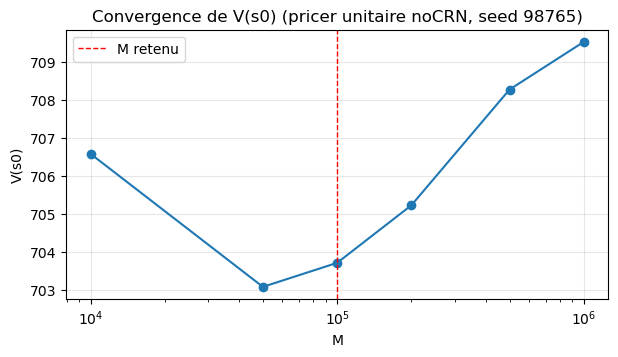

In [6]:
RUN_CONVERGENCE = True
M_CONV = [10_000, 50_000, 100_000, 200_000, 500_000, 1_000_000]
if SMOKE:
    M_CONV = [1_000, 2_000, 5_000]
if RUN_CONVERGENCE:
    df_conv = FR.convergence_study(cfg, market, pf, M_CONV)
    display(df_conv)
    plt.figure(figsize=(7, 3.5))
    plt.plot(df_conv.index, df_conv["V"], marker="o")
    plt.axvline(cfg.mc.n_paths, color="r", ls="--", lw=1, label="M retenu")
    plt.xscale("log"); plt.xlabel("M"); plt.ylabel("V(s0)"); plt.grid(alpha=.3); plt.legend()
    plt.title("Convergence de V(s0) (pricer unitaire noCRN, seed %d)" % cfg.mc.seed_pricing)
    plt.show()

## 5. LE full repricing (unitaire, noCRN, même seed) — caché, reprenable

`benchmark` mesure un pricing unitaire par produit et projette le coût total.
`run_full_repricing` ne calcule que ce qui manque ; une interruption (Ctrl-C) est reprise
exactement au dernier checkpoint. `n_workers > 1` parallélise par (étape, produit).

In [7]:
bench = FR.benchmark(cfg, market, pf)

1 repricing complet du portefeuille (100 pricings unitaires, M=100,000) : 5.34 s
Projection full repricing (20001 pricings / produit) : 106793 s = 29.7 h (sequentiel)


In [8]:
RUN_FR_HERE = True     # False : ne rien calculer ici (ex. calcul lancé via run_all.py)
N_WORKERS = 1          # ex. os.cpu_count() pour paralléliser (temps par pricing toujours mesurés)

if RUN_FR_HERE:
    FR.run_full_repricing(cfg, market, pf, n_workers=N_WORKERS)
st = FR.status(cfg, pf)
display(st[FR.stages(cfg)].apply(lambda c: c.value_counts()).fillna(0).astype(int))
print("Cache :", FR.fr_dir(cfg))

Scenarios charges du cache : cache/scenarios/238c57ffe7ce
Full repricing : 300 taches (etape x produit), 0 deja en cache, 300 a calculer -> cache/full_repricing/b2e1aee835de
  [300/300] 10j  p100 (d=25) :  10000/10000  0.064s/pricing  ETA tache 0s     
Full repricing : session terminee en 80178 s (mur).


,s0,1j,10j
ok,100,100,100


Cache : cache/full_repricing/b2e1aee835de


### 5.1 Résultats du full repricing : valeurs, temps mesurés, VaR / ES

In [9]:
fr = FR.FullRepricing(cfg, pf)

display(Markdown("**Par produit : prix en s0, contribution, temps mesurés (somme des pricings par étape)**"))
df_prod = fr.product_table()
display(df_prod)

display(Markdown("**Par groupe : V0, part, temps mesurés**"))
df_grp = A.fr_group_table(fr, cfg)
display(df_grp)

display(Markdown("**VaR 99 % / ES 97,5 % / ES 99 % — full repricing (référence), par groupe et portefeuille**"))
df_fr = A.fr_risk_table(fr, cfg)
display(df_fr)

**Par produit : prix en s0, contribution, temps mesurés (somme des pricings par étape)**

,d,type,sens,K,T,alpha,prix_unitaire_s0,contribution_s0,t_s0_s,t_1j_s,t_10j_s,t_1_pricing_moy_s
id,,,,,,,,,,,,
1,5,geo,Call,91.493852,1.0,1.0,14.675253,14.675253,0.030478,176.125639,155.566074,0.016585
2,5,geo,Call,96.576844,2.0,1.0,15.022171,15.022171,0.031868,145.627385,151.144229,0.014839
3,5,geo,Call,101.659836,3.0,1.0,15.161554,15.161554,0.030597,148.835759,152.535866,0.015069
4,5,geo,Put,106.742827,4.0,-1.0,24.369619,-24.369619,0.040603,149.771007,154.048430,0.015192
5,5,geo,Put,111.825819,5.0,-1.0,30.125185,-30.125185,0.028963,149.597940,152.378099,0.015099
...,...,...,...,...,...,...,...,...,...,...,...,...
96,25,WO,Call,90.000000,1.0,1.0,1.042301,1.042301,0.080976,643.322984,629.275464,0.063631
97,25,WO,Call,95.000000,2.0,1.0,0.639899,0.639899,0.079480,640.179692,632.417137,0.063631
98,25,WO,Call,100.000000,3.0,1.0,0.470069,0.470069,0.080378,639.732086,643.346596,0.064155


**Par groupe : V0, part, temps mesurés**

,V0_d,part_V0_pct,t_FR_s0_s,t_FR_1j_s,t_FR_10j_s,t_1_pricing_moy_s
d,,,,,,
5,38.105252,5.414919,0.555705,3300.518299,3295.609644,0.016491
10,82.653824,11.745462,0.789116,5555.995062,5594.101716,0.027876
15,131.323890,18.661687,1.031542,8176.015892,8066.504232,0.040607
20,190.383152,27.054261,1.309744,10449.758812,10340.181529,0.051976
25,261.242453,37.123671,1.638075,12727.937735,12586.064122,0.063286
total,703.708571,100.000000,5.324182,40210.225800,39882.461243,0.040047


**VaR 99 % / ES 97,5 % / ES 99 % — full repricing (référence), par groupe et portefeuille**

V0     L_mean       L_std        L_min        L_max      VaR_99     ES_97_5  n_tail_ES_97_5       ES_99  n_tail_ES_99        t_FR_s  t_FR_par_scenario_s  n_pricings
perimetre    horizon                                                                                                                                                                              
d=5          1j        38.105252  -0.340408   18.001533   -70.879589    70.653607   40.767595   41.121419             250   47.471140           100   3300.518299             0.330052      200000
             10j       38.105252  -2.352031   57.014138  -246.526359   199.846949  121.154666  122.035223             250  139.519377           100   3295.609644             0.329561      200000
d=10         1j        82.653824  -0.513481   19.944201   -78.769817    79.455600   45.037455   45.590969             250   52.482619           100   5555.995062             0.555600      200000
             10j       82.653824  -3.561883   63.181759  -274.250756   224.986811  134.059609  134.865918             250  153.856908           100   5594.101716             0.559410      200000
d=15         1j       131.323890  -0.712879   22.874982   -96.599582    98.812754   51.449449   52.310984             250   60.403479           100   8176.015892             0.817602      200000
             10j      131.323890  -4.888754   72.547116  -341.967229   274.328347  151.785633  153.994253             250  176.104818           100   8066.504232             0.806650      200000
d=20         1j       190.383152  -0.883500   26.633873  -104.619312   116.366021   59.379869   60.522852             250   69.656218           100  10449.758812             1.044976      200000
             10j      190.383152  -6.262835   84.610143  -367.823541   319.960200  174.124917  177.217033             250  202.093140           100  10340.181529             1.034018      200000
d=25         1j       261.242453  -0.978615   31.058425  -124.231699   126.270495   70.471502   70.309354             250   80.461644           100  12727.937735             1.272794      200000
             10j      261.242453  -7.511950   98.735639  -442.904570   348.676742  206.251112  205.016306             250  232.515453           100  12586.064122             1.258606      200000
portefeuille 1j       703.708571  -3.428883  116.038608  -460.958423   491.558477  262.740197  264.175308             250  304.984487           100  40210.225800             4.021023     1000000
             10j      703.708571 -24.577453  368.123795 -1620.387294  1367.799050  774.412904  777.342157             250  889.194650           100  39882.461243             3.988246     1000000

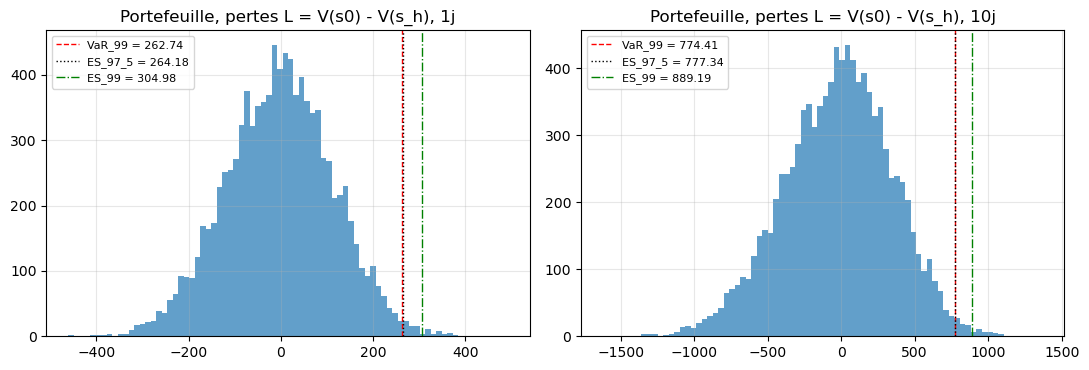

In [10]:
fig, ax = plt.subplots(1, len(HS), figsize=(5.5*len(HS), 3.8))
for a, h in zip(np.atleast_1d(ax), HS):
    L = fr.V0() - fr.values(h)
    a.hist(L, bins=80, alpha=.7)
    for k, ls, c in [("VaR_99", "--", "r"), ("ES_97_5", ":", "k"), ("ES_99", "-.", "g")]:
        v = df_fr.loc[("portefeuille", h), k]
        a.axvline(v, color=c, ls=ls, lw=1, label="%s = %.2f" % (k, v))
    a.set_title("Portefeuille, pertes L = V(s0) - V(s_h), %s" % h)
    a.legend(fontsize=8); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 6. Proxies par groupe — construction (nœuds CRN) et évaluation, cachées

Si un proxy est en cache, il est relu **sans** MoCaX. Un échec de fit (ex. `SVD did not converge`)
est enregistré et affiché ; `RETRY_FAILED = True` pour réessayer.

In [11]:
RETRY_FAILED = False
PROXY = {}
for d in DIMS:
    try:
        PROXY[d] = run_group_proxy(cfg, market, pf, d, S, mocaxpy, me,
                                   retry_failed=RETRY_FAILED)
    except RuntimeError as exc:
        print("d=%d : %s" % (d, exc))

Proxy d=5 (full_cheb) : GroupPricer(d=5, n_products=20, M=100000, seed=98765, CRN), init 0.01s
  Full CT d=5 : 3125 noeuds (5^5)
  CT d=5 noeuds :  3125/3125  0.062s/noeud  ETA 0s     
  eval s0   :      1 points en 0.000s (0 hors boite)
  eval 1j   :  10000 points en 0.112s (0 hors boite)
  eval 10j  :  10000 points en 0.112s (0 hors boite)
Proxy d=10 (tt) : GroupPricer(d=10, n_products=20, M=100000, seed=98765, CRN), init 0.01s
  TT d=10 : degre 5, n_train demande 1500 -> 1500 points (1500 uniques), grille pleine 6.05e+07
  TT d=10 noeuds :  1500/1500  0.076s/noeud  ETA 0s     
  TT d=10 : fit ALS (1 restart(s))...
  eval s0   :      1 points en 0.002s (0 hors boite)
  eval 1j   :  10000 points en 6.466s (0 hors boite)
  eval 10j  :  10000 points en 6.481s (0 hors boite)
Proxy d=15 (tt) : GroupPricer(d=15, n_products=20, M=100000, seed=98765, CRN), init 0.02s
  TT d=15 : degre 5, n_train demande 2500 -> 2500 points (2500 uniques), grille pleine 4.7e+11
  TT d=15 noeuds :  2500/2500  

In [12]:
rows = []
for d, r in PROXY.items():
    b = r["build"]
    row = dict(d=d, méthode=r["method"], statut=r["status"], cache=r["root"],
               n_noeuds=b.get("n_nodes"), t_init_crn_s=b.get("t_init_crn"),
               t_noeuds_s=b.get("t_nodes"), t_fit_s=b.get("t_fit"), t_build_s=b.get("t_build"),
               mesuré_le=b.get("timestamp"), machine=b.get("host"), erreur=b.get("error"))
    info = b.get("info", {}) or {}
    row.update({k: info.get(k) for k in ("ranks", "rank_max", "saturated", "val_err",
                                         "n_train_req", "n_train", "n_train_unique",
                                         "best_restart", "restart_val_errs",
                                         "restart_errors", "err_ex_ante")})
    row["params"] = b.get("params")
    rows.append(row)
display(Markdown("**Construction des proxies : temps mesurés, rangs, erreurs**"))
display(pd.DataFrame(rows).set_index("d"))

**Construction des proxies : temps mesurés, rangs, erreurs**

,méthode,statut,cache,n_noeuds,t_init_crn_s,t_noeuds_s,t_fit_s,t_build_s,mesuré_le,machine,erreur,ranks,rank_max,saturated,val_err,n_train_req,n_train,n_train_unique,best_restart,restart_val_errs,restart_errors,err_ex_ante,params
d,,,,,,,,,,,,,,,,,,,,,,,
5,full_cheb,ok,cache/proxies/d05_full_cheb_9735659d59a0,3125,0.008613,194.011768,0.000676,194.021057,2026-09-29T18:54:34,Oussama,None,None,NaN,None,NaN,NaN,NaN,NaN,NaN,None,None,0.435148,{'degree': 4}
10,tt,ok,cache/proxies/d10_tt_6fffd89e278c,1500,0.009855,113.883705,35.852712,149.746272,2026-09-29T18:57:48,Oussama,None,"[1, 2, 2, 3, 3, 4, 2, 5, 2, 2, 1]",5.0,False,1.526489,1500.0,1500.0,1500.0,0.0,[1.5264887220926653],[None],NaN,"{'degree': 5, 'n_train': 1500, 'max_rank': 10, 'tolerance': 0.0001, 'rel_tol..."
15,tt,ok,cache/proxies/d15_tt_7da441903682,2500,0.015135,255.625284,290.329454,545.969873,2026-09-29T19:00:31,Oussama,None,"[1, 3, 2, 4, 2, 2, 5, 2, 2, 3, 4, 4, 4, 6, 3, 1]",6.0,False,1.512116,2500.0,2500.0,2500.0,0.0,[1.51211638247743],[None],NaN,"{'degree': 5, 'n_train': 2500, 'max_rank': 10, 'tolerance': 0.0001, 'rel_tol..."
20,tt,ok,cache/proxies/d20_tt_5d97e8b30fe1,3500,0.021499,419.646990,667.261286,1086.929775,2026-09-29T19:10:05,Oussama,None,"[1, 3, 2, 3, 2, 5, 2, 2, 4, 2, 2, 3, 3, 2, 3, 4, 3, 2, 3, 3, 1]",5.0,False,0.991076,3500.0,3500.0,3500.0,0.0,[0.9910759971257903],[None],NaN,"{'degree': 5, 'n_train': 3500, 'max_rank': 8, 'tolerance': 0.0001, 'rel_tole..."
25,tt,ok,cache/proxies/d25_tt_f390f3069072,5000,0.029673,640.745527,1362.443979,2003.219179,2026-09-29T19:28:56,Oussama,None,"[1, 3, 2, 2, 2, 2, 4, 2, 2, 2, 2, 3, 2, 2, 3, 2, 4, 2, 4, 2, 3, 3, 3, 2, 4, 1]",4.0,False,1.721156,5000.0,5000.0,5000.0,0.0,[1.7211556554523213],[None],NaN,"{'degree': 5, 'n_train': 5000, 'max_rank': 8, 'tolerance': 0.0001, 'rel_tole..."


## 7. Proxies vs full repricing : VaR / ES, erreurs, temps, speed-ups

* `t_FR` : somme des temps **mesurés** des pricings unitaires du périmètre sur l'horizon.
* `t_eval` : évaluation du proxy sur les mêmes 10 000 scénarios.
* `speedup_online = t_FR / t_eval` ; `speedup_total = t_FR(s0+1j+10j) / (t_build + t_eval(s0+1j+10j))`.
* Portefeuille par proxy = **somme des évaluations** des proxies de groupe (un groupe en échec est
  remplacé par son full repricing et **signalé** dans le libellé).

In [13]:
df_cmp, df_t, PF_PROXY = A.proxy_tables(fr, PROXY, cfg)
df_syn = A.summary_table(df_cmp, cfg)

display(Markdown("**Synthèse : mesures de risque FR vs proxy (écarts en %)**"))
display(df_syn)
display(Markdown("**Détail complet (toutes colonnes)**"))
display(df_cmp)
display(Markdown("**Temps mesurés et speed-ups**"))
display(df_t)

**Synthèse : mesures de risque FR vs proxy (écarts en %)**

methode   VaR_99_FR  VaR_99_proxy  dVaR_99_pct  ES_97_5_FR  ES_97_5_proxy  dES_97_5_pct    ES_99_FR  ES_99_proxy  dES_99_pct  erel_sc_mean        t_FR_s   t_eval_s  speedup_online
perimetre    horizon                                                                                                                                                                                           
d=5          1j           full_cheb   40.767595     40.763430    -0.010216   41.121419      41.116657     -0.011579   47.471140    47.464943   -0.013054      0.000065   3300.518299   0.111958    29479.857516
             10j          full_cheb  121.154666    121.117090    -0.031014  122.035223     122.010402     -0.020339  139.519377   139.495102   -0.017400      0.000174   3295.609644   0.111779    29483.137351
d=10         1j                  tt   45.037455     44.649299    -0.861852   45.590969      45.217331     -0.819543   52.482619    52.034658   -0.853543      0.011469   5555.995062   6.465819      859.287163
             10j                 tt  134.059609    131.513760    -1.899043  134.865918     132.529734     -1.732227  153.856908   150.686181   -2.060829      0.009393   5594.101716   6.480598      863.207680
d=15         1j                  tt   51.449449     51.092342    -0.694092   52.310984      51.951669     -0.686883   60.403479    59.911671   -0.814205      0.004706   8176.015892  13.915145      587.562389
             10j                 tt  151.785633    146.995192    -3.156057  153.994253     148.865822     -3.330275  176.104818   169.302520   -3.862641      0.006564   8066.504232  13.941146      578.611269
d=20         1j                  tt   59.379869     57.698316    -2.831857   60.522852      58.761550     -2.910145   69.656218    67.527889   -3.055476      0.009537  10449.758812  22.091113      473.029981
             10j                 tt  174.124917    165.613649    -4.888024  177.217033     168.520171     -4.907464  202.093140   191.321021   -5.330275      0.010260  10340.181529  22.049429      468.954608
d=25         1j                  tt   70.471502     68.367605    -2.985457   70.309354      68.130284     -3.099260   80.461644    77.856450   -3.237809      0.006530  12727.937735  29.606068      429.909758
             10j                 tt  206.251112    194.601490    -5.648271  205.016306     193.520313     -5.607355  232.515453   218.299240   -6.114094      0.008586  12586.064122  29.672153      424.170909
portefeuille 1j       somme proxies  262.740197    257.666003    -1.931259  264.175308     259.575492     -1.741198  304.984487   299.365288   -1.842454      0.007209  40210.225800  72.190104      557.004682
             10j      somme proxies  774.412904    750.362974    -3.105569  777.342157     750.325321     -3.475540  889.194650   854.821455   -3.865655      0.008043  39882.461243  72.255106      551.967378

**Détail complet (toutes colonnes)**

methode       V0_FR    V0_proxy       dV0   VaR_99_FR  VaR_99_proxy    dVaR_99  dVaR_99_pct  ES_97_5_FR  ES_97_5_proxy   dES_97_5  dES_97_5_pct    ES_99_FR  ES_99_proxy     dES_99  dES_99_pct  erel_sc_max  erel_sc_mean  \
perimetre    horizon                                                                                                                                                                                                                                     
d=5          1j           full_cheb   38.105252   38.103275 -0.001978   40.767595     40.763430  -0.004165    -0.010216   41.121419      41.116657  -0.004761     -0.011579   47.471140    47.464943  -0.006197   -0.013054     0.000591      0.000065   
             10j          full_cheb   38.105252   38.103275 -0.001978  121.154666    121.117090  -0.037575    -0.031014  122.035223     122.010402  -0.024821     -0.020339  139.519377   139.495102  -0.024276   -0.017400     0.001027      0.000174   
d=10         1j                  tt   82.653824   81.679287 -0.974536   45.037455     44.649299  -0.388156    -0.861852   45.590969      45.217331  -0.373638     -0.819543   52.482619    52.034658  -0.447962   -0.853543     0.015876      0.011469   
             10j                 tt   82.653824   81.679287 -0.974536  134.059609    131.513760  -2.545849    -1.899043  134.865918     132.529734  -2.336184     -1.732227  153.856908   150.686181  -3.170727   -2.060829     0.075086      0.009393   
d=15         1j                  tt  131.323890  130.708153 -0.615737   51.449449     51.092342  -0.357107    -0.694092   52.310984      51.951669  -0.359315     -0.686883   60.403479    59.911671  -0.491808   -0.814205     0.009728      0.004706   
             10j                 tt  131.323890  130.708153 -0.615737  151.785633    146.995192  -4.790442    -3.156057  153.994253     148.865822  -5.128432     -3.330275  176.104818   169.302520  -6.802298   -3.862641     0.105462      0.006564   
d=20         1j                  tt  190.383152  188.482243 -1.900909   59.379869     57.698316  -1.681553    -2.831857   60.522852      58.761550  -1.761303     -2.910145   69.656218    67.527889  -2.128329   -3.055476     0.016871      0.009537   
             10j                 tt  190.383152  188.482243 -1.900909  174.124917    165.613649  -8.511268    -4.888024  177.217033     168.520171  -8.696862     -4.907464  202.093140   191.321021 -10.772119   -5.330275     0.120981      0.010260   
d=25         1j                  tt  261.242453  259.453839 -1.788614   70.471502     68.367605  -2.103896    -2.985457   70.309354      68.130284  -2.179070     -3.099260   80.461644    77.856450  -2.605194   -3.237809     0.013254      0.006530   
             10j                 tt  261.242453  259.453839 -1.788614  206.251112    194.601490 -11.649621    -5.648271  205.016306     193.520313 -11.495992     -5.607355  232.515453   218.299240 -14.216213   -6.114094     0.109307      0.008586   
portefeuille 1j       somme proxies  703.708571  698.426797 -5.281774  262.740197    257.666003  -5.074194    -1.931259  264.175308     259.575492  -4.599816     -1.741198  304.984487   299.365288  -5.619199   -1.842454     0.012815      0.007209   
             10j      somme proxies  703.708571  698.426797 -5.281774  774.412904    750.362974 -24.049930    -3.105569  777.342157     750.325321 -27.016836     -3.475540  889.194650   854.821455 -34.373195   -3.865655     0.101678      0.008043   

                       eabs_max  eabs_mean  bias_mean        t_FR_s   t_eval_s  speedup_online  n_hors_boite groupes_en_repli_FR  
perimetre    horizon                                                                                                              
d=5          1j        0.022824   0.002517  -0.000823   3300.518299   0.111958    29479.857516           0.0                 NaN  
             10j       0.056934   0.009670   0.007234   3295.609644   0.111779    29483.137351           0.0                 NaN  
d=1

**Temps mesurés et speed-ups**

,methode,statut,n_noeuds,t_init_crn_s,t_nodes_s,t_noeud_moy_s,t_fit_s,t_build_s,t_eval_s0_s,t_FR_s0_s,t_eval_1j_s,t_FR_1j_s,t_eval_10j_s,t_FR_10j_s,speedup_online_1j,speedup_online_10j,t_FR_total_s,t_proxy_total_s,speedup_total,err_ex_ante,rangs,rang_max,sature,val_err,n_train,n_train_uniques,restart_retenu,erreurs_restarts
perimetre,,,,,,,,,,,,,,,,,,,,,,,,,,,,
d=5,full_cheb,ok,3125,0.008613,194.011768,0.062084,0.000676,194.021057,0.000061,0.555705,0.111958,3300.518299,0.111779,3295.609644,29479.857516,29483.137351,6596.683647,194.244856,33.960661,0.435148,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
d=10,tt,ok,1500,0.009855,113.883705,0.075922,35.852712,149.746272,0.001675,0.789116,6.465819,5555.995062,6.480598,5594.101716,859.287163,863.207680,11150.885894,162.694363,68.538858,NaN,"[1, 2, 2, 3, 3, 4, 2, 5, 2, 2, 1]",5.0,False,1.526489,1500.0,1500.0,0.0,[None]
d=15,tt,ok,2500,0.015135,255.625284,0.102250,290.329454,545.969873,0.003339,1.031542,13.915145,8176.015892,13.941146,8066.504232,587.562389,578.611269,16243.551666,573.829503,28.307279,NaN,"[1, 3, 2, 4, 2, 2, 5, 2, 2, 3, 4, 4, 4, 6, 3, 1]",6.0,False,1.512116,2500.0,2500.0,0.0,[None]
d=20,tt,ok,3500,0.021499,419.646990,0.119899,667.261286,1086.929775,0.004337,1.309744,22.091113,10449.758812,22.049429,10340.181529,473.029981,468.954608,20791.250085,1131.074655,18.381855,NaN,"[1, 3, 2, 3, 2, 5, 2, 2, 4, 2, 2, 3, 3, 2, 3, 4, 3, 2, 3, 3, 1]",5.0,False,0.991076,3500.0,3500.0,0.0,[None]
d=25,tt,ok,5000,0.029673,640.745527,0.128149,1362.443979,2003.219179,0.005351,1.638075,29.606068,12727.937735,29.672153,12586.064122,429.909758,424.170909,25315.639933,2062.502752,12.274233,NaN,"[1, 3, 2, 2, 2, 2, 4, 2, 2, 2, 2, 3, 2, 2, 3, 2, 4, 2, 4, 2, 3, 3, 3, 2, 4, 1]",4.0,False,1.721156,5000.0,5000.0,0.0,[None]
portefeuille,somme proxies,ok,15625,0.084776,1623.913274,NaN,2355.888107,3979.886157,0.014762,5.324182,72.190104,40210.225800,72.255106,39882.461243,557.004682,551.967378,80098.011224,4124.346129,19.420778,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


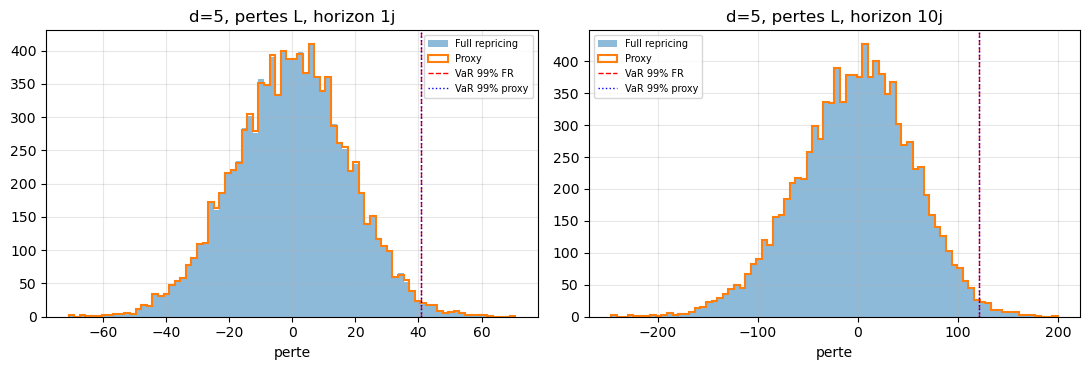

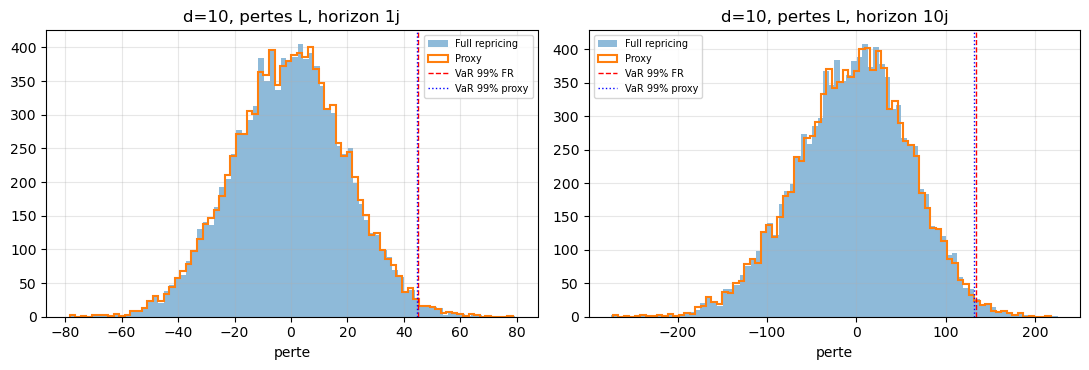

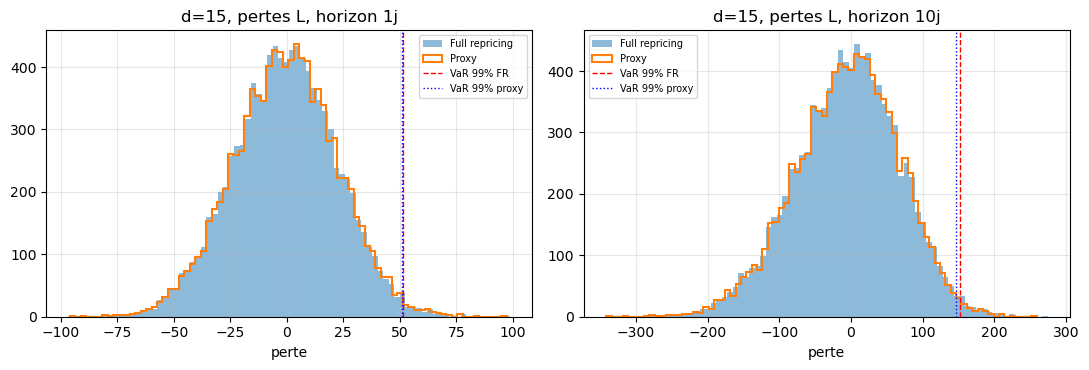

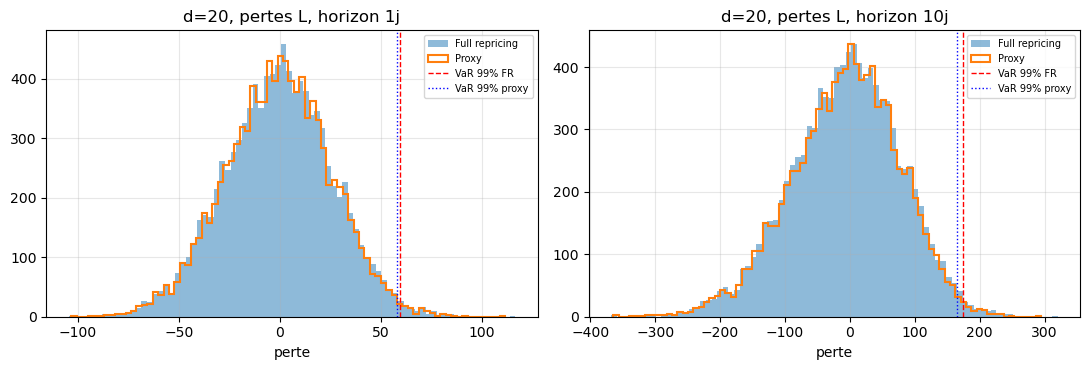

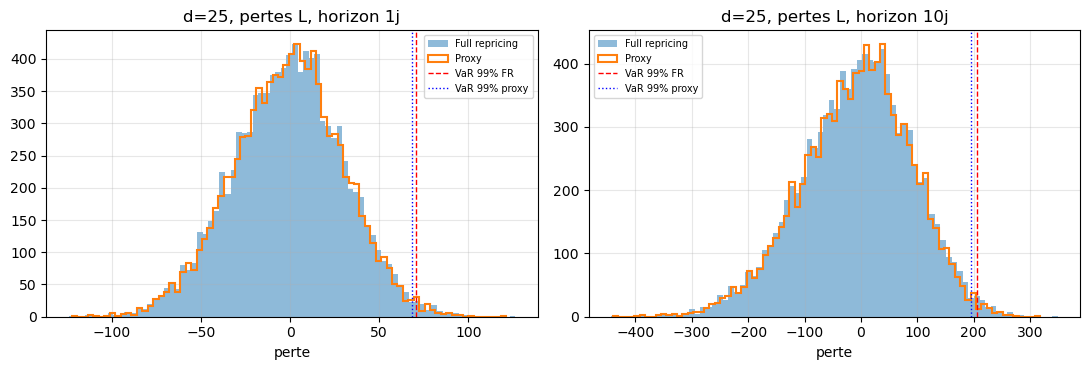

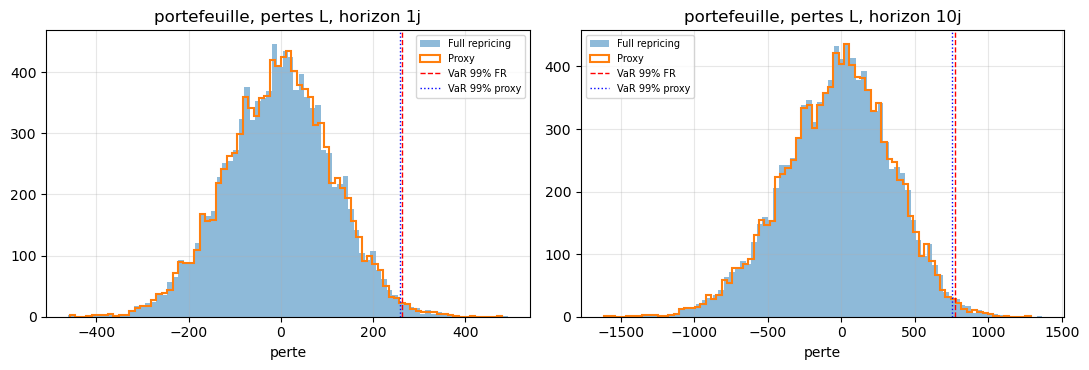

Tableaux (CSV + JSON) et figures écrits dans cache/results/4f38b3993681


In [14]:
RES_DIR = A.results_dir(cfg, PROXY)
A.save_all(RES_DIR, dict(fr_risque=df_fr, fr_groupes=df_grp, fr_produits=df_prod,
                         proxy_vs_fr=df_cmp, proxy_temps=df_t, synthese=df_syn))
A.plot_losses(fr, PROXY, PF_PROXY, cfg, root=RES_DIR, show=True)
print("Tableaux (CSV + JSON) et figures écrits dans", RES_DIR)

## 8. Inventaire du cache

In [15]:
rows = []
for dirpath, _dirs, files in os.walk(cfg.run.cache_dir):
    if not files:
        continue
    size = sum(os.path.getsize(os.path.join(dirpath, f)) for f in files)
    rows.append(dict(dossier=os.path.relpath(dirpath, cfg.run.cache_dir),
                     n_fichiers=len(files), taille_Mo=size / 1e6))
df_inv = pd.DataFrame(rows).set_index("dossier")
display(df_inv.groupby(lambda p: "/".join(p.split(os.sep)[:2])).sum())

,n_fichiers,taille_Mo
dossier,,
convergence,1,0.001720
full_repricing/b2e1aee835de,902,32.205361
proxies/d05_full_cheb_9735659d59a0,9,0.383404
proxies/d10_tt_6fffd89e278c,10,0.376877
proxies/d15_tt_7da441903682,10,0.718243
proxies/d20_tt_5d97e8b30fe1,10,1.072894
proxies/d25_tt_f390f3069072,10,1.596450
results,1,0.000098
results/4f38b3993681,18,0.341827
